# Nutrition5k: resultados generales

Un finalista por familia, con todas sus semillas (media; `val_sd` es la SD entre semillas). En `FINALISTS`, escribir
el nombre del run elegido de cada familia (con o sin `-s<semilla>`). Con `None` se toma la configuración con más
semillas (las finales de la etapa 3) y, entre ellas, la de menor validación media.
Los detalles de cada familia están en `notebooks/<familia>/results.ipynb`.

In [1]:
import os
from pathlib import Path

if Path("/workspace").is_dir():  # RunPod
    os.chdir("/root/thesis-multimodal-health-ai")
elif Path.cwd().name == "notebooks":
    os.chdir("..")

from nutrition5k.results import baseline_row, bar_targets, cost, finalists, load_runs, target_table

SPLIT = "pilot"         # "full" o "pilot"
MODE = "complete"
FINALISTS = {"mobilenet": None, "hybrid_mobile": None, "plain_vit": None, "hierarchical": None}

final = finalists(load_runs(FINALISTS, SPLIT, MODE), FINALISTS)
final[["family", "backbone", "run", "seeds", "val_mean_pmae", "val_sd", "test_mean_pmae", "test_clean_mean_pmae",
       "params_M"]].round(2)

,family,backbone,run,seeds,val_mean_pmae,val_sd,test_mean_pmae,test_clean_mean_pmae,params_M
25,mobilenet,v4m-r256,v4m-r256-ft_2-single-h0-256-complete-pilot-fbn...,3,53.01,4.12,60.24,60.24,8.76
28,hybrid_mobile,fastvit_sa12,fastvit_sa12-ft_all-single-h512-224-complete-p...,1,62.31,NaN,59.92,59.92,11.21
31,plain_vit,deit_s,deit_s-ft_all-single-h512-224-complete-pilot-f...,1,53.23,NaN,63.55,63.55,22.00
36,hierarchical,swin_t,swin_t-ft_all-single-h512-224-complete-pilot-f...,1,61.88,NaN,59.07,59.07,28.05


## Error por objetivo (validación) y por familia

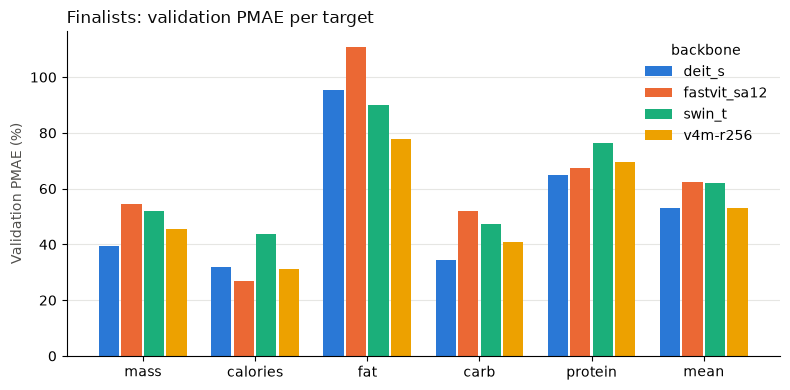

In [2]:
display(target_table(final, "backbone"))
bar_targets(final, "backbone", "Finalists: validation PMAE per target")

## Error frente a coste (Q7)

MACs y latencia en la CPU de esta máquina; la latencia que cuenta es la del iPhone.

/home/abello/Desktop/harness-thesis-multimodal-health-ai/code/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


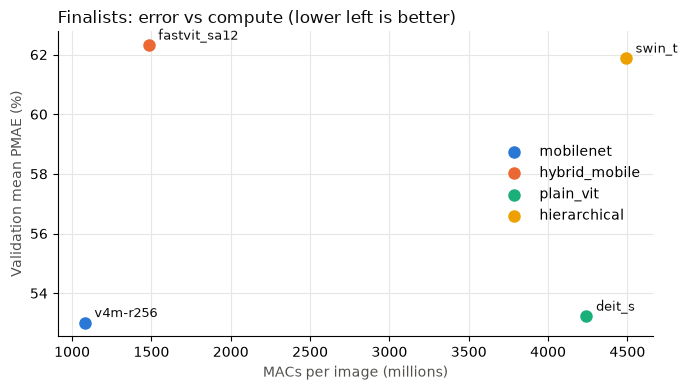

,family,val_mean_pmae,params_M,size_MB,MMACs,cpu_ms,gpu_memory_gb,sec_per_epoch,gpu
backbone,,,,,,,,,
v4m-r256,mobilenet,53.01,8.76,35.47,1079.29,20.95,NaN,9.90,None
fastvit_sa12,hybrid_mobile,62.31,11.21,45.17,1481.81,33.87,NaN,13.39,None
deit_s,plain_vit,53.23,22.00,88.03,4241.16,36.67,NaN,13.27,None
swin_t,hierarchical,61.88,28.05,112.24,4490.32,51.88,NaN,18.26,None


In [3]:
cost(final, "backbone", "Finalists: error vs compute (lower left is better)").round(2)